In [2]:
import pandas as pd                  # 판다스: 표 형태의 재료 정리
import numpy as np                    # 넘파이: 숫자 계산 담당
import matplotlib.pyplot as plt      # 맷플롯립: 그래프 그리기
import seaborn as sns                # 시본: 예쁜 통계 그래프 그리기

from sklearn.preprocessing import StandardScaler, OneHotEncoder  # 사이킷런 전처리: 숫자 표준화, 글자 분류
from sklearn.decomposition import PCA                              # 피씨에이: 많은 정보를 적은 차원으로 압축
from sklearn.model_selection import train_test_split               # 트레인 테스트 스플릿: 학습용과 시험용 데이터 분리

from tensorflow.keras.models import Sequential  # 시퀀셜: 층을 순서대로 쌓는 신경망 틀
from tensorflow.keras.layers import Dense, Dropout  # 덴스: 정보 연결 계산층 / 드롭아웃: 일부 연결을 잠시 꺼서 과적합 방지
from tensorflow.keras.callbacks import EarlyStopping  # 얼리 스토핑: 성적이 더 좋아지지 않으면 학습 중단

In [3]:
# 폰트지정
plt.rcParams['font.family'] = 'Malgun Gothic'

In [7]:
# 1. 데이터 로드
train_df = pd.read_csv("dataset/train_titanic.csv")
test_df = pd.read_csv("dataset/test_titanic.csv")

In [ ]:
# 1.1 전처리 전 데이터 확인

print("=== 전처리 전 데이터 (train_df) ===")  # 전처리하기 전 원본 재료 확인
print(train_df.head())                     # 헤드: 맨 위 데이터 5줄 보기

print("\n=== 데이터 기본 정보 ===")         # 데이터의 전체적인 정보 확인
print(train_df.info())                     # 인포:재료 종류와 수량 확인

print("\n=== 결측값 수 ===")                # 빠진 재료가 몇 개인지 확인
print(train_df.isnull().sum())             # 이즈널: 빈칸을 찾아 열마다 개수 세기

=== 전처리 전 데이터 (train_df) ===
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450

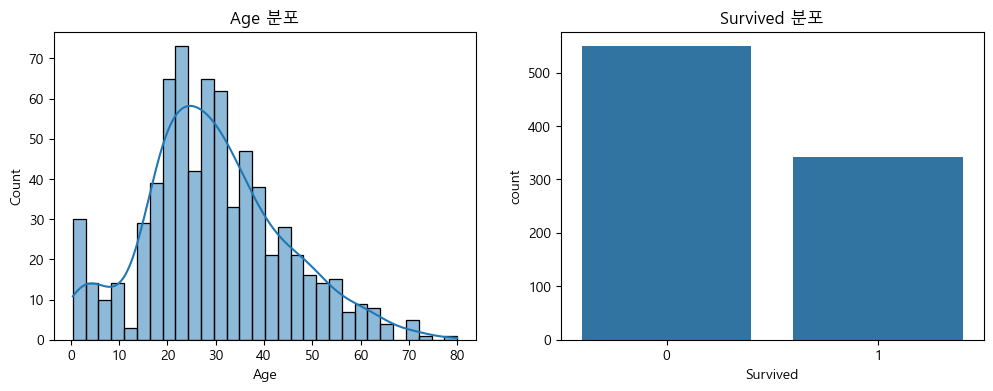

In [9]:
# 주요 특성 분포 시각화

plt.figure(figsize=(12, 4))                  # 그래프 전체 크기 설정 (가로 12, 세로 4)
plt.subplot(1, 2, 1)                         # 그래프를 1행 2열로 나누고 첫 번째 자리 선택
sns.histplot(train_df['Age'].dropna(), bins=30, kde=True)  # 나이 분포 확인, 빈칸은 제외, 구간은 30개
plt.title('Age 분포')                        # 첫 번째 그래프 제목

plt.subplot(1, 2, 2)                         # 두 번째 그래프 자리 선택
sns.countplot(x='Survived', data=train_df)   # 생존 여부별 인원수 세기
plt.title('Survived 분포')                   # 두 번째 그래프 제목 (서브플롯) = 한 화면에 그래프 두 개 배치하기

plt.show()                                   # 그래프 화면에 출력

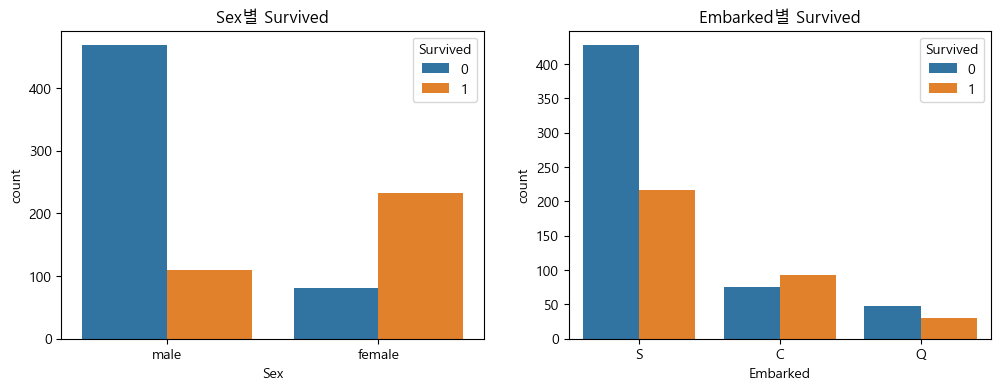

In [10]:
plt.figure(figsize=(12, 4))  # 그래프 전체 크기 설정
plt.subplot(1, 2, 1)  # 1행 2열 중 첫 번째 그래프 자리
sns.countplot(x='Sex', hue='Survived', data=train_df)  # 성별에 따른 생존·사망 인원수 비교
plt.title('Sex별 Survived')  # 그래프 제목

plt.subplot(1, 2, 2)  # 1행 2열 중 두 번째 그래프 자리
sns.countplot(x='Embarked', hue='Survived', data=train_df)  # 탑승 항구별 생존·사망 인원수 비교
plt.title('Embarked별 Survived')  # 그래프 제목
plt.show()  # 그래프 화면에 출력
# 전체적으로 하는 일: 성별과 탑승 항구에 따라 생존자와 사망자가 얼마나 차이 나는지 그래프로 비교하는 코드야.

In [11]:
# 2. 데이터 전처리 (데이터 손질하기)

# 결측값 처리 (빠진 재료 채우기)
train_df = train_df.assign(Age=train_df['Age'].fillna(train_df['Age'].median()))  # 훈련 데이터 나이 빈칸 → 나이 중앙값으로 채우기
test_df = test_df.assign(Age=test_df['Age'].fillna(test_df['Age'].median()))  # 시험 데이터 나이 빈칸 → 나이 중앙값으로 채우기

train_df = train_df.assign(Embarked=train_df['Embarked'].fillna(train_df['Embarked'].mode()[0]))  # 훈련 데이터 탑승 항구 빈칸 → 가장 많이 나온 항구로 채우기
test_df = test_df.assign(Fare=test_df['Fare'].fillna(test_df['Fare'].median()))  # 시험 데이터 요금 빈칸 → 요금 중앙값으로 채우기

In [12]:
# 🍔 범주형 및 예측 데이터 준비 x,y 분리 /정답없이 예측할 재료만 준비하는과정

features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']  # 햄버거 재료 목록: 예측에 사용할 7가지 특성 선택

X_train = train_df[features]  # 훈련용 재료 준비: AI가 학습할 문제지
y_train = train_df['Survived']  # 정답표 준비: 실제 생존 여부 (0=사망, 1=생존)
X_test = test_df[features]  # 시험용 재료 준비: AI가 생존 여부를 예측할 문제지


In [13]:
# 3. 원핫 인코딩 (글자로 된 재료를 숫자표로 바꾸기)

ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')  # 원핫 인코더: 성별·탑승 항구 같은 글자 재료를 숫자 0과 1로 변환하는 기계

cat_features_train = ohe.fit_transform(X_train[['Sex', 'Embarked']])  # 훈련용 데이터의 성별·항구를 학습하고 숫자로 변환
cat_feature_names = ohe.get_feature_names_out(['Sex', 'Embarked'])  # 변환된 숫자표의 새로운 열 이름 확인
cat_features_test = ohe.transform(X_test[['Sex', 'Embarked']])  # 시험용 데이터도 훈련용과 같은 기준으로 숫자 변환

# 🍔 이 코드가 하는 일:
# 글자로 적힌 재료 이름을 AI가 계산할 수 있도록 숫자표로 바꾸는 과정!

In [ ]:
# 🍔 수치형 데이터 준비 및 표준화

num_features_train = X_train[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']]  # 넘 피처스 트레인(수치형 특성): 훈련용 숫자 재료 선택
num_features_test = X_test[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']]  # 넘 피처스 테스트: 시험용 숫자 재료 선택

scaler = StandardScaler()  # 스탠더드 스케일러(표준화 도구): 숫자들의 기준과 크기를 맞추는 기계

num_features_train_scaled = scaler.fit_transform(num_features_train)  # 핏 트랜스폼: 훈련용 숫자의 평균·표준편차를 계산하고 기준에 맞춰 변환
num_features_test_scaled = scaler.transform(num_features_test)  # 트랜스폼: 훈련용에서 정한 기준으로 시험용 숫자도 변환

# 🍔 이 코드가 하는 일:
# 키, 몸무게, 가격처럼 숫자 크기가 제각각인 재료를
# 같은 기준으로 맞춰 AI가 공평하게 계산하도록 손질하는 과정!
# fit_transform은 기준을 만들고 변환, transform은 이미 만든 기준으로 변환이야.

In [ ]:
# 🍔 데이터 결합 (숫자 재료 + 글자 재료 합치기)

X_train_combined = np.hstack([num_features_train_scaled, cat_features_train])  # 넘파이 에이치스택(가로 결합): 훈련용 숫자 재료와 글자 재료를 옆으로 붙이기
X_test_combined = np.hstack([num_features_test_scaled, cat_features_test])  # 훈련용과 똑같이 시험용 숫자 재료와 글자 재료도 가로로 붙이기

# 🍔 이 코드가 하는 일:
# 따로 손질해 둔 숫자 재료와 글자 재료를 하나의 햄버거 재료표로 합쳐서
# AI에게 한꺼번에 전달할 수 있도록 만드는 과정!
#숫자 재료 + 글자 재료 = 하나의 재료표!

In [18]:
# 🍔 3.1 원핫 인코딩 후 데이터 확인

X_train_combined_df = pd.DataFrame(  # 피디 데이터프레임(표 만들기): 합쳐 놓은 숫자 재료와 글자 재료를 보기 쉬운 표로 변환
    X_train_combined,  # 숫자 재료와 글자 재료가 합쳐진 훈련용 데이터
    columns=list(num_features_train.columns) + list(cat_feature_names)  # 컬럼스(열 이름): 원래 숫자 재료 이름 + 원핫 인코딩으로 새로 생긴 열 이름 붙이기
)

print("\n=== 원핫 인코딩 후 데이터 (train) ===")  # 출력할 내용의 제목 표시
print(X_train_combined_df.head())  # 헤드(앞부분 보기): 표의 맨 위 5개 행만 출력

print("\n=== 원핫 인코딩 후 특성 수 ===")  # 특성 개수를 확인하는 제목 표시
print(f"특성 수: {X_train_combined.shape[1]}")  # 셰이프(표의 모양): shape[1]은 열 개수, 즉 AI가 학습에 사용할 특성 개수

# 🍔 이 코드가 하는 일:
# 손질해서 합쳐 놓은 재료들을 다시 이름표가 붙은 표로 만들고,
# 위에서 5줄을 확인한 다음 AI가 사용할 재료 종류가 총 몇 개인지 세어보는 과정!


=== 원핫 인코딩 후 데이터 (train) ===
     Pclass       Age     SibSp     Parch      Fare  Sex_female  Sex_male  \
0  0.827377 -0.565736  0.432793 -0.473674 -0.502445         0.0       1.0   
1 -1.566107  0.663861  0.432793 -0.473674  0.786845         1.0       0.0   
2  0.827377 -0.258337 -0.474545 -0.473674 -0.488854         1.0       0.0   
3 -1.566107  0.433312  0.432793 -0.473674  0.420730         1.0       0.0   
4  0.827377  0.433312 -0.474545 -0.473674 -0.486337         0.0       1.0   

   Embarked_C  Embarked_Q  Embarked_S  
0         0.0         0.0         1.0  
1         1.0         0.0         0.0  
2         0.0         0.0         1.0  
3         0.0         0.0         1.0  
4         0.0         0.0         1.0  

=== 원핫 인코딩 후 특성 수 ===
특성 수: 10


In [19]:
# 🍔 4. PCA 적용 (많은 재료 정보를 핵심만 남겨 압축하기)

pca = PCA(n_components=0.95)  # 피씨에이(주성분 분석): 전체 데이터의 정보량(분산)을 약 95% 유지하도록 특성 수를 자동으로 줄이는 도구
# n_components(엔 컴포넌츠, 구성 요소 개수): 남길 정보의 기준 설정
# 0.99 = 정보량 99% 유지, 정보 보존을 더 중요하게 생각할 때
# 0.95 = 정보량 95% 유지, 정보 보존과 압축의 균형을 고려할 때
# 0.90 = 정보량 90% 유지, 더 많이 압축하고 싶을 때
# 0.80 = 정보량 80% 유지, 강하게 압축하고 싶을 때
# ※ 숫자가 낮을수록 정보가 더 많이 줄어들 수 있고, 속도가 반드시 빨라지는 것은 아님

X_train_pca = pca.fit_transform(X_train_combined)  # 핏 트랜스폼: 훈련용 데이터의 핵심 정보와 압축 기준을 학습한 뒤 차원 축소
X_test_pca = pca.transform(X_test_combined)  # 트랜스폼: 훈련용에서 정한 압축 기준을 시험용 데이터에도 똑같이 적용

# 🍔 이 코드가 하는 일:
# 햄버거 재료가 너무 많으면 모든 재료를 하나씩 들고 다니기 힘드니까,
# 맛을 결정하는 핵심 정보는 최대한 남기고 비슷하거나 겹치는 정보는 압축하는 과정!
# 훈련용 재료로 압축 기준을 먼저 정하고, 시험용 재료에도 같은 기준을 적용한다.

In [20]:
# 🍔 4.1 PCA 적용 후 데이터 확인

print("\n=== PCA 적용 후 데이터 (train) ===")  # PCA 압축이 끝난 훈련용 데이터의 제목 출력
print(pd.DataFrame(X_train_pca).head())  # 피디 데이터프레임(표 만들기): 압축된 데이터를 표로 바꿔 맨 위 5개 행 확인

print("\n=== PCA 후 특성 수 ===")  # 압축 후 특성 개수를 확인하는 제목 출력
print(f"특성 수: {X_train_pca.shape[1]}")  # 셰이프(데이터 모양)의 [1]: 압축 후 열의 개수, 즉 남은 특성 수 확인

print("\n=== PCA 설명된 분산 비율 ===")  # 원래 데이터의 정보가 얼마나 유지됐는지 확인하는 제목 출력
print(pca.explained_variance_ratio_)  # 익스플레인드 베리언스 레이시오(설명된 분산 비율): 각 주성분이 보존한 정보 비율 출력

# 🍔 이 코드가 하는 일:
# 재료를 압축한 뒤 ① 압축된 표를 확인하고,
# ② 재료 종류가 몇 개로 줄었는지 세고,
# ③ 각 압축 재료가 원래 정보 중 얼마만큼을 담고 있는지 확인하는 과정!


=== PCA 적용 후 데이터 (train) ===
          0         1         2         3         4         5         6
0  1.189309  0.192409 -0.110413  0.659347 -0.288647 -0.084718  0.192395
1 -1.928325 -0.283466 -0.261757  0.478090  1.101178  0.310490 -0.695613
2  0.952821 -0.283762 -0.244249 -0.375087  0.717514  0.471797  0.655214
3 -1.477304 -0.221825 -0.097151  0.492243  1.142331 -0.463277  0.425057
4  0.884103 -0.794282  0.416630  0.052776 -0.452524  0.185091  0.287513

=== PCA 후 특성 수 ===
특성 수: 7

=== PCA 설명된 분산 비율 ===
[0.29349319 0.28200411 0.12503667 0.1013726  0.06904592 0.06537826
 0.04703816]


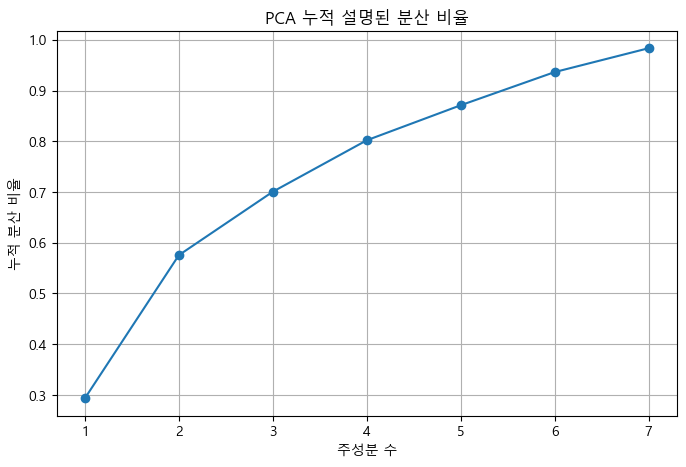

In [21]:
# 🍔 PCA 설명된 분산 비율 시각화

plt.figure(figsize=(8, 5))  # 피겨(그래프 화면): 가로 8, 세로 5 크기로 그래프 공간 만들기

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),  # 주성분 번호를 1번부터 마지막까지 순서대로 생성
    pca.explained_variance_ratio_.cumsum(),  # 씨섬(누적합): 주성분별 정보 보존 비율을 앞에서부터 계속 더하기
    marker='o'  # 마커(표시점): 각 주성분의 누적 정보 보존 비율을 동그라미로 표시
)

plt.title('PCA 누적 설명된 분산 비율')  # 그래프 제목: PCA가 원래 정보량을 얼마나 보존했는지 표시
plt.xlabel('주성분 수')  # 엑스 레이블: 가로축은 주성분 개수
plt.ylabel('누적 분산 비율')  # 와이 레이블: 세로축은 지금까지 보존한 정보 비율
plt.grid(True)  # 그리드(격자): 그래프에 눈금 보조선 표시
plt.show()  # 쇼(출력): 완성된 그래프 화면에 표시

# 🍔 이 코드가 하는 일:
# 주성분을 하나씩 추가할 때마다 원래 햄버거 재료 정보가
# 얼마나 누적해서 보존되는지 선 그래프로 확인하는 과정!
# 예를 들어 그래프가 0.95에 도달하면 원래 정보의 약 95%를 보존했다는 뜻!

In [ ]:
# 🍔 5. MLP 모델 구성 (신경망 햄버거 주방 만들기)

model = Sequential([  # 시퀀셜(순차형): 신경망 층을 위에서 아래로 순서대로 쌓는 모델 틀

    Dense(32, activation='relu', input_shape=(X_train_pca.shape[1],)),  # 덴스(완전 연결층): 압축된 재료 정보를 받아 뉴런 32개가 서로 계산
    # activation(액티베이션, 활성화 함수)='relu'(렐루): 음수는 0으로 만들고 양수는 통과시켜 다음 계산으로 전달
    # input_shape(인풋 셰이프, 입력 형태): 입력 데이터의 특성 개수 설정
    # X_train_pca.shape[1]: PCA 적용 후 남은 특성의 열 개수

    Dropout(0.3),  # 드롭아웃(일부 뉴런 끄기): 학습할 때 뉴런의 30%를 임시로 꺼서 특정 뉴런에만 의존하는 현상과 과적합을 줄임

    Dense(16, activation='relu'),  # 두 번째 덴스층: 뉴런 16개가 앞 층에서 받은 정보를 다시 계산

    Dropout(0.3),  # 두 번째 드롭아웃: 학습할 때 뉴런의 30%를 임시로 꺼서 과적합 방지

    Dense(1, activation='sigmoid')  # 마지막 덴스층: 뉴런 1개로 생존 여부 예측
    # 시그모이드(시그모이드, 0~1 출력 함수): 결과를 0과 1 사이의 값으로 변환
    # 예: 0.8이면 생존 가능성을 약 80%로 예측한 것

])

# 🍔 이 코드가 하는 일:
# PCA로 압축한 재료를 첫 번째 조리대(뉴런 32개)에서 계산하고,
# 중간중간 일부 조리사를 쉬게 해 특정 조리사에게만 의존하지 않도록 한 뒤,
# 두 번째 조리대(뉴런 16개)에서 한 번 더 계산하고,
# 마지막 조리사(뉴런 1개)가 생존 가능성을 0~1 사이 숫자로 내놓는 신경망 주방!
#
# 전체 구조: 입력 → 32개 뉴런 → 일부 끄기 → 16개 뉴런 → 일부 끄기 → 생존 예측 1개

c:\ai\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
# 🍔 5.1 MLP 모델 학습 준비 (요리사에게 조리 규칙 알려주기)

model.compile(
    optimizer='adam',  # 옵티마이저(최적화 도구): AI가 예측을 틀릴 때마다 가중치를 조정해 정답에 가까워지도록 만드는 방법
    loss='binary_crossentropy',  # 로스(손실 함수): 생존/사망처럼 정답이 0 또는 1인 문제에서 예측이 얼마나 틀렸는지 계산
    metrics=['accuracy']  # 메트릭스(평가 지표): 학습 결과를 정확도(맞힌 개수 ÷ 전체 개수)로 확인
)

# 🍔 이 코드가 하는 일:
# ① 아담이라는 요리사가 레시피(가중치)를 수정하고,
# ② 손실 함수가 정답과 얼마나 차이 나는지 채점하고,
# ③ 정확도로 전체 주문 중 몇 개를 맞혔는지 평가하도록
# AI 주방의 학습 규칙을 정하는 과정!

In [24]:
# 🍔 6. 학습 (AI에게 햄버거 조리법 가르치기)

early_stopping = EarlyStopping(
    monitor='val_loss',  # 모니터(관찰 대상): 검증용 데이터의 손실값을 지켜보겠다는 뜻
    patience=5,  # 페이션스(기다림): 검증 손실이 5번 연속 좋아지지 않으면 학습 중단
    restore_best_weights=True  # 리스토어 베스트 웨이츠(최고 가중치 복원): 학습 중 가장 성적이 좋았던 시점의 가중치로 되돌림
)

history = model.fit(
    X_train_pca,  # 훈련용 입력 데이터: PCA로 압축한 재료 정보
    y_train,  # 정답 데이터: 실제 생존 여부 (0=사망, 1=생존)
    epochs=50,  # 에폭(전체 학습 횟수): 훈련용 데이터를 최대 50바퀴 반복해서 학습
    batch_size=32,  # 배치 사이즈(묶음 크기): 데이터 32개씩 나눠서 학습
    validation_split=0.2,  # 밸리데이션 스플릿(검증 데이터 분리): 훈련 데이터의 20%를 학습 중간 점검용으로 분리
    callbacks=[early_stopping],  # 콜백(학습 중간 관리자): 얼리 스토핑을 연결해 조건에 따라 학습을 멈추도록 설정
    verbose=1  # 버보스(출력 수준): 학습 진행 상황을 화면에 표시
)

# 🍔 이 코드가 하는 일:
# AI 요리사에게 최대 50번 조리 연습을 시키되,
# 전체 재료 중 20%는 중간 시험용으로 남겨두고,
# 성적이 5번 연속 좋아지지 않으면 연습을 멈춘 다음
# 가장 성적이 좋았던 시점의 조리법을 되살리는 과정!

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.5702 - loss: 0.7095 - val_accuracy: 0.6425 - val_loss: 0.6669
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6110 - loss: 0.6772 - val_accuracy: 0.6425 - val_loss: 0.6130
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6264 - loss: 0.6362 - val_accuracy: 0.6592 - val_loss: 0.5726
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6489 - loss: 0.6091 - val_accuracy: 0.6872 - val_loss: 0.5416
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6461 - loss: 0.5947 - val_accuracy: 0.7263 - val_loss: 0.5161
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6826 - loss: 0.5808 - val_accuracy: 0.7654 - val_loss: 0.4952
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6882 - loss: 0.5637 - val_accuracy: 0.8101 - val_loss: 0.4780
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7360 - loss: 0.5480 - val_accuracy: 0.8268 - val_loss

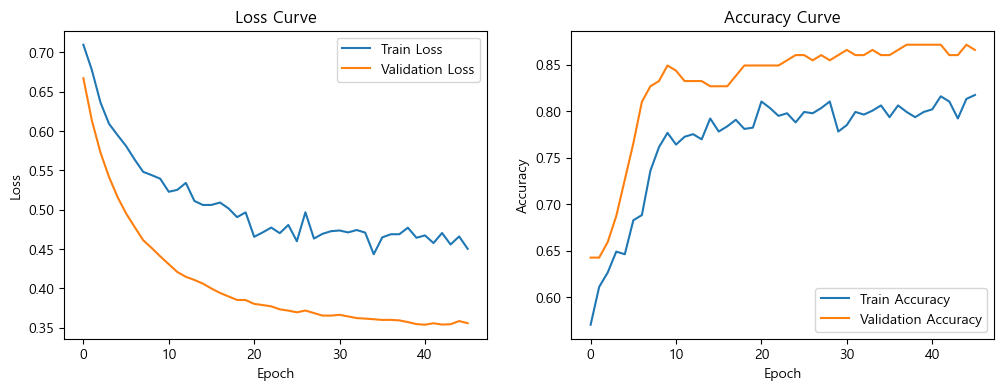

In [25]:
# 🍔 7. 학습 결과 시각화 (AI 요리사의 연습 성적표 확인)

plt.figure(figsize=(12, 4))  # 피겨(그래프 화면): 가로 12, 세로 4 크기로 그래프 공간 만들기

plt.subplot(1, 2, 1)  # 서브플롯(그래프 자리): 1행 2열 중 첫 번째 그래프 선택
plt.plot(history.history['loss'], label='Train Loss')  # 훈련 손실: AI가 연습하면서 얼마나 틀렸는지 선 그래프로 표시
plt.plot(history.history['val_loss'], label='Validation Loss')  # 검증 손실: 연습에 사용하지 않은 검증 데이터에서 얼마나 틀렸는지 표시
plt.title('Loss Curve')  # 로스 커브(손실 곡선): 틀린 정도가 학습하면서 어떻게 변했는지 확인
plt.xlabel('Epoch')  # 엑스 레이블: 가로축은 전체 데이터 학습 횟수
plt.ylabel('Loss')  # 와이 레이블: 세로축은 틀린 정도
plt.legend()  # 레전드(범례): 훈련 손실과 검증 손실의 선이 무엇인지 표시

plt.subplot(1, 2, 2)  # 두 번째 그래프 자리 선택
plt.plot(history.history['accuracy'], label='Train Accuracy')  # 훈련 정확도: 연습 데이터에서 정답을 맞힌 비율 표시
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')  # 검증 정확도: 검증 데이터에서 정답을 맞힌 비율 표시
plt.title('Accuracy Curve')  # 애큐러시 커브(정확도 곡선): 정답을 맞힌 비율이 어떻게 변했는지 확인
plt.xlabel('Epoch')  # 가로축은 전체 데이터 학습 횟수
plt.ylabel('Accuracy')  # 세로축은 정답을 맞힌 비율
plt.legend()  # 훈련 정확도와 검증 정확도의 선을 구분해서 표시

plt.show()  # 쇼(출력): 두 그래프를 화면에 표시

# 🍔 이 코드가 하는 일:
# 왼쪽 그래프는 AI 요리사가 얼마나 틀렸는지 확인하고,
# 오른쪽 그래프는 정답을 얼마나 잘 맞히는지 확인하는 성적표!
# 훈련 성적만 좋아지고 검증 성적이 나빠진다면,
# 연습 문제만 외우는 과적합이 생겼는지 의심할 수 있다.

In [26]:
# 🍔 8. 테스트 데이터 예측 (AI 요리사가 최종 시험 문제 풀기)

y_pred = (model.predict(X_test_pca) > 0.5).astype(int).flatten()
# model.predict(X_test_pca): 모델이 시험용 데이터를 보고 생존 확률을 예측
# predict(프리딕트, 예측하다): AI가 정답을 추측하는 기능
# > 0.5: 예측 확률이 0.5보다 크면 True(참), 아니면 False(거짓)로 구분
# 0.5 이상이면 생존(1), 0.5 미만이면 사망(0)으로 판단
# ※ 코드의 > 0.5는 정확히 0.5일 때 False이므로, 0.5 이상을 기준으로 하려면 >= 0.5로 작성해야 함
# astype(int): 에이 타입(자료형 변환): True는 1, False는 0으로 변환
# flatten(): 플래튼(평탄화): [[1], [0], [1]]처럼 생긴 배열을 [1, 0, 1] 한 줄로 펼침

# 🍔 이 코드가 하는 일:
# AI 요리사가 시험용 손님들의 생존 확률을 계산한 다음,
# 50%를 기준으로 생존은 1, 사망은 0으로 판정하고,
# 제출하기 편하도록 결과를 한 줄짜리 숫자표로 정리하는 과정!

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step


In [27]:
# 🍔 9. 예측 결과 저장 (AI가 푼 시험 답안 제출하기)

submission = pd.DataFrame({  # 피디 데이터프레임(표 만들기): 예측 결과를 제출용 표로 정리
    'PassengerId': test_df['PassengerId'],  # 패신저 아이디(승객 번호): 시험용 데이터에 있는 승객 고유 번호
    'Survived': y_pred  # 서바이브드(생존 여부): AI가 예측한 결과 (0=사망, 1=생존)
})

submission.to_csv('./dataset/submission.csv', index=False)  # 투 씨에스브이( CSV 파일로 저장): dataset 폴더에 submission.csv 파일 생성
# index=False(인덱스 제외): 판다스가 자동으로 붙이는 행 번호는 저장하지 않음

print("\n=== 예측 결과 상위 5개 ===")  # 예측 결과를 확인할 제목 출력
print(submission.head())  # 헤드(앞부분 보기): 제출용 표에서 위쪽 5개 행만 화면에 출력

# 🍔 이 코드가 하는 일:
# AI 요리사가 시험 문제를 풀어 내놓은 생존 답안에 승객 번호를 붙이고,
# 제출용 답안지(CSV 파일)로 저장한 다음,
# 맨 위 5개를 열어 제대로 작성됐는지 확인하는 과정!


=== 예측 결과 상위 5개 ===
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1


In [28]:
# 1. 데이터 결합
# 숫자 재료와 글자 재료를 가로로 붙여 하나의 훈련용·시험용 데이터로 만든다.

# 2. 원핫 인코딩 후 데이터 확인 및 PCA 적용
# 합쳐진 데이터를 표로 만들고 상위 5개 행과 특성 개수를 확인한다.
# PCA(주성분 분석)를 적용해 전체 정보량의 95%를 유지하면서 특성 수를 줄인다.
# 훈련용 데이터로 압축 기준을 학습하고 시험용 데이터에도 동일하게 적용한다.
# 압축 후 데이터와 특성 수, 설명된 분산 비율을 확인한다.
# 누적 설명된 분산 비율을 그래프로 시각화한다.

# 3. MLP 모델 구성
# 신경망 층을 순서대로 쌓아 모델을 만든다.
# 첫 번째 층: 뉴런 32개, ReLU 활성화 함수
# 첫 번째 Dropout: 뉴런의 30%를 임시로 꺼서 과적합 방지
# 두 번째 층: 뉴런 16개, ReLU 활성화 함수
# 두 번째 Dropout: 뉴런의 30%를 임시로 꺼서 과적합 방지
# 출력층: 뉴런 1개, Sigmoid 활성화 함수로 생존 확률 출력

# 4. 모델 학습 규칙 설정
# Adam 옵티마이저로 가중치를 조정한다.
# Binary Crossentropy 손실 함수로 예측 오차를 계산한다.
# Accuracy 지표로 예측 정확도를 평가한다.

# 5. 모델 학습 및 결과 시각화
# 최대 50회 학습하고 데이터를 32개씩 묶어서 학습한다.
# 훈련 데이터의 20%를 검증용 데이터로 분리한다.
# 검증 손실이 5회 연속 좋아지지 않으면 학습을 중단한다.
# 학습 중 가장 성적이 좋았던 가중치를 복원한다.
# 손실 곡선과 정확도 곡선을 그래프로 확인한다.

# 6. 테스트 데이터 예측 및 결과 저장
# 테스트 데이터의 생존 확률을 예측한다.
# 예측 확률이 0.5 이상이면 생존(1), 0.5 미만이면 사망(0)으로 판정한다.
# 승객 번호와 예측 결과를 제출용 표로 만든다.
# submission.csv 파일로 저장하고 상위 5개 결과를 확인한다.

# 🍔 전체 과정:
# 재료 합치기 → 재료 압축하기 → AI 주방 만들기 → 학습 규칙 정하기
# → 요리 연습 및 성적 확인 → 실전 예측 후 답안 제출!